# 02 · Experimento central: quanto se perde ao baratear os sensores?

**Cronograma:** dia 9 (plano C), adiantado para 16/11/2026

**Pergunta:** a pulseira de pesquisa (Empatica E4) custa caro. Quanto desempenho na detecção de estresse se perde quando ficamos só com os sinais que sensores baratos, ligados a um ESP32, conseguem medir?

| Conjunto | Sensores | Equivalente barato | Indicadores |
|---|---|---|---|
| `so_fc` | frequência cardíaca (FC) | sensor óptico de pulso (ex.: MAX30102) | 5 |
| `baixo_custo` | FC + temperatura da pele + movimento | + termistor/DS18B20 + acelerômetro (MPU6050) | 11 |
| `baixo_custo_eda` | + atividade eletrodérmica (EDA) | + sensor GSR | 18 (todos os sensores de pulso da E4) |

**Desenho do experimento** (detalhes em `src/models/train.py`):

- tarefa binária: estresse (TSST) vs. não estresse (baseline + diversão), como em Schmidt et al. (2018);
- validação **LOSO** (deixa uma pessoa de fora): cada participante é avaliado por um modelo que nunca viu dados dele, como num aluno novo;
- **calibração por pessoa**: cada indicador vira a diferença em relação aos 5 primeiros minutos de repouso da própria pessoa; esses 5 minutos ficam fora da avaliação;
- configuração principal: janelas de 60 s com passo de 30 s. As versões sem calibração (bruta) e com janelas de 120 s servem de checagem de robustez.

**Cuidado de leitura:** o "baixo custo" aqui é **simulado** com sinais da própria E4, que são mais limpos que os de sensores baratos. Os números são um **teto** para o hardware barato.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, f1_score
from sklearn.model_selection import LeaveOneGroupOut

from src.data.preprocess import conjuntos, normalizar_por_baseline
from src.data.wesad import SUBJECTS, load_wrist, subject_info
from src.models.train import FEATURES, carregar, modelos

FIG_DIR = ROOT / "results" / "figures"
MET_DIR = ROOT / "results" / "metrics"

# paleta categórica fixa (uma cor por conjunto de sensores, igual em todas as figuras)
CONJ = ["so_fc", "baixo_custo", "baixo_custo_eda"]
NOME = {"so_fc": "Só FC", "baixo_custo": "Baixo custo\n(FC+temp+mov.)", "baixo_custo_eda": "Baixo custo + EDA"}
NOME1 = {k: v.replace("\n", " ") for k, v in NOME.items()}
COR = {"so_fc": "#2a78d6", "baixo_custo": "#eb6834", "baixo_custo_eda": "#1baf7a"}
MODELOS = ["lr", "lda", "rf", "xgb"]
NOME_MOD = {"lr": "Regressão logística", "lda": "LDA", "rf": "Random Forest", "xgb": "XGBoost"}
COR_MOD = {"lr": "#2a78d6", "lda": "#eb6834", "rf": "#1baf7a", "xgb": "#eda100"}
TINTA, TINTA2, GRADE = "#222222", "#666666", "#e6e6e6"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#999999", "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})
pd.set_option("display.precision", 3)

## 1. Resultado principal: comparação dos conjuntos de sensores

Métricas agregadas do LOSO (todas as previsões dos 15 participantes juntas), lidas de `results/metrics/loso_wesad*.csv`, geradas por `python -m src.models.train`.

In [2]:
CONFIGS = {"60 s, calibrado (principal)": "loso_wesad",
           "60 s, sem calibração": "loso_wesad_bruto",
           "120 s, calibrado": "loso_wesad_w120_p60"}
resumo = pd.concat([pd.read_csv(MET_DIR / f"{arq}.csv").assign(config=nome) for nome, arq in CONFIGS.items()])

principal = resumo[resumo.config == "60 s, calibrado (principal)"]
tab = (principal.pivot(index="modelo", columns="conjunto", values="f1_macro")[CONJ]
       .loc[["maioria"] + MODELOS].rename(columns=NOME1, index={"maioria": "Maioria (referência)", **NOME_MOD}))
print("F1 macro, LOSO, 60 s calibrado")
tab

F1 macro, LOSO, 60 s calibrado


conjunto,Só FC,Baixo custo (FC+temp+mov.),Baixo custo + EDA
modelo,,,
Maioria (referência),0.397,0.397,0.397
Regressão logística,0.821,0.835,0.930
LDA,0.826,0.820,0.895
Random Forest,0.815,0.826,0.948
XGBoost,0.813,0.812,0.921


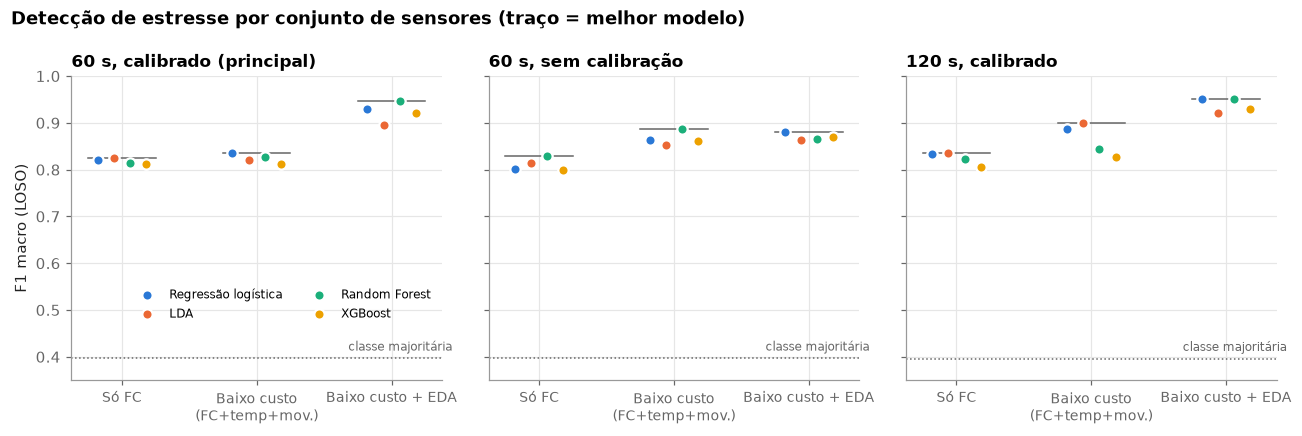

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharey=True)
x = np.arange(len(CONJ))
desloc = dict(zip(MODELOS, [-0.18, -0.06, 0.06, 0.18]))
for ax, (nome, _) in zip(axes, CONFIGS.items()):
    r = resumo[resumo.config == nome]
    for i, c in enumerate(CONJ):
        v = r[(r.conjunto == c) & r.modelo.isin(MODELOS)].f1_macro
        ax.plot([i - 0.25, i + 0.25], [v.max()] * 2, color=TINTA2, lw=1)
    for m in MODELOS:
        v = [r[(r.conjunto == c) & (r.modelo == m)].f1_macro.item() for c in CONJ]
        ax.scatter(x + desloc[m], v, s=46, color=COR_MOD[m], edgecolor="white", linewidth=1.5,
                   zorder=3, label=NOME_MOD[m])
    maioria = r[r.modelo == "maioria"].f1_macro.mean()
    ax.axhline(maioria, color=TINTA2, ls=":", lw=1)
    ax.text(2.45, maioria + 0.01, "classe majoritária", ha="right", va="bottom", color=TINTA2, fontsize=8)
    ax.set_xticks(x, [NOME[c] for c in CONJ], fontsize=9)
    ax.set_title(nome, loc="left")
    ax.set_ylim(0.35, 1.0)
axes[0].set_ylabel("F1 macro (LOSO)")
axes[0].legend(loc="lower right", fontsize=8, ncol=2, bbox_to_anchor=(1.0, 0.16))
fig.suptitle("Detecção de estresse por conjunto de sensores (traço = melhor modelo)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_comparacao_conjuntos.png")
plt.show()

### Quanto se perde ao tirar o sensor de EDA?

Diferença de F1 macro em relação ao conjunto completo (`baixo_custo_eda`), para o melhor modelo de cada conjunto em cada configuração.

In [4]:
melhor = (resumo[resumo.modelo.isin(MODELOS)].sort_values("f1_macro")
          .groupby(["config", "conjunto"]).tail(1).set_index(["config", "conjunto"]))
linhas = []
for nome in CONFIGS:
    ref = melhor.loc[(nome, "baixo_custo_eda"), "f1_macro"]
    for c in CONJ:
        l = melhor.loc[(nome, c)]
        linhas.append({"configuração": nome, "conjunto": NOME1[c], "melhor modelo": NOME_MOD[l.modelo],
                       "F1 macro": l.f1_macro, "AUROC": l.auroc, "acur. balanceada": l.acuracia_balanceada,
                       "perda de F1 vs. completo": l.f1_macro - ref})
perdas = pd.DataFrame(linhas)
perdas.to_csv(MET_DIR / "02_perda_por_conjunto.csv", index=False)
perdas

,configuração,conjunto,melhor modelo,F1 macro,AUROC,acur. balanceada,perda de F1 vs. completo
0,"60 s, calibrado (principal)",Só FC,LDA,0.826,0.892,0.812,-0.122
1,"60 s, calibrado (principal)",Baixo custo (FC+temp+mov.),Regressão logística,0.835,0.907,0.840,-0.112
2,"60 s, calibrado (principal)",Baixo custo + EDA,Random Forest,0.948,0.988,0.950,0.000
3,"60 s, sem calibração",Só FC,Random Forest,0.828,0.913,0.832,-0.052
4,"60 s, sem calibração",Baixo custo (FC+temp+mov.),Random Forest,0.887,0.949,0.885,0.007
5,"60 s, sem calibração",Baixo custo + EDA,Regressão logística,0.880,0.955,0.887,0.000
6,"120 s, calibrado",Só FC,LDA,0.836,0.917,0.820,-0.116
7,"120 s, calibrado",Baixo custo (FC+temp+mov.),LDA,0.900,0.935,0.890,-0.052
8,"120 s, calibrado",Baixo custo + EDA,Random Forest,0.952,0.992,0.955,0.000


## 2. Curvas ROC

A curva ROC mostra o compromisso entre detectar o estresse (sensibilidade) e disparar alarmes falsos, para todos os limiares de decisão, e não só para o limiar de 0,5. Usamos a **Random Forest** em todos os conjuntos, para comparar sensores com o mesmo modelo (é o melhor modelo do conjunto completo e o melhor de Schmidt et al., 2018, no pulso).

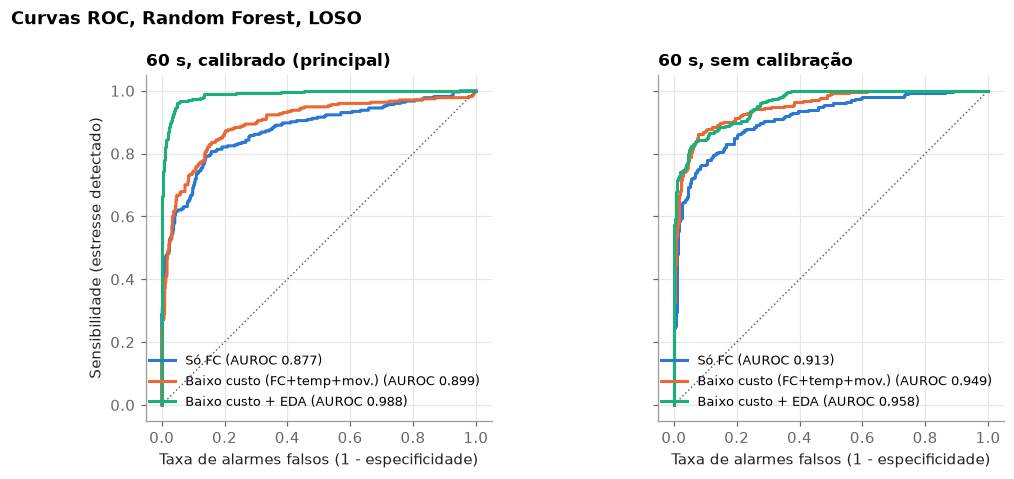

In [5]:
MOD = "rf"
prev = pd.read_csv(MET_DIR / "loso_wesad_previsoes.csv")
prev_bruto = pd.read_csv(MET_DIR / "loso_wesad_bruto_previsoes.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
for ax, (p, titulo) in zip(axes, [(prev, "60 s, calibrado (principal)"), (prev_bruto, "60 s, sem calibração")]):
    for c in CONJ:
        prob = p[f"prob__{c}__{MOD}"]
        fpr, tpr, _ = roc_curve(p.estresse, prob)
        ax.plot(fpr, tpr, color=COR[c], lw=2, label=f"{NOME1[c]} (AUROC {roc_auc_score(p.estresse, prob):.3f})")
    ax.plot([0, 1], [0, 1], color=TINTA2, ls=":", lw=1)
    ax.set_title(titulo, loc="left")
    ax.set_xlabel("Taxa de alarmes falsos (1 - especificidade)")
    ax.legend(loc="lower right", fontsize=8.5)
    ax.set_aspect("equal")
axes[0].set_ylabel("Sensibilidade (estresse detectado)")
fig.suptitle("Curvas ROC, Random Forest, LOSO", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_roc.png")
plt.show()

## 3. Desempenho por participante

As métricas agregadas escondem a variação entre pessoas. Para uma pulseira escolar isso importa: um modelo com média boa ainda pode falhar sempre com o mesmo aluno.

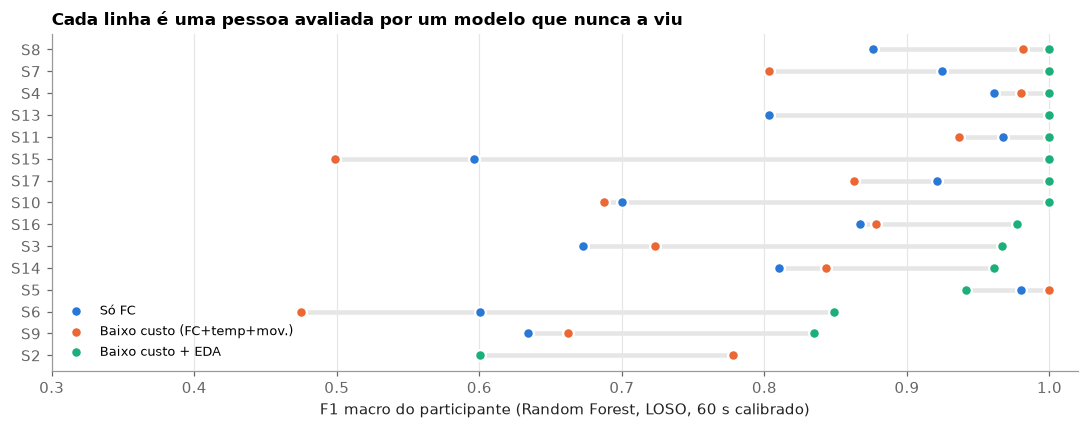

conjunto  Só FC  Baixo custo (FC+temp+mov.)  Baixo custo + EDA
mean      0.806                       0.807              0.942
std       0.137                       0.171              0.109
min       0.596                       0.475              0.600
max       0.980                       1.000              1.000


In [6]:
pp = pd.read_csv(MET_DIR / "loso_wesad_por_participante.csv")
pp = pp[pp.modelo == MOD].pivot(index="subject", columns="conjunto", values="f1_macro")[CONJ]
pp = pp.sort_values("baixo_custo_eda")

fig, ax = plt.subplots(figsize=(10, 4))
y = np.arange(len(pp))
for i, s in enumerate(pp.index):
    ax.plot([pp.loc[s].min(), pp.loc[s].max()], [i, i], color=GRADE, lw=3, zorder=1, solid_capstyle="round")
for c in CONJ:
    ax.scatter(pp[c], y, s=50, color=COR[c], edgecolor="white", linewidth=1.5, zorder=3, label=NOME1[c])
ax.set_yticks(y, pp.index)
ax.set_xlabel("F1 macro do participante (Random Forest, LOSO, 60 s calibrado)")
ax.set_xlim(0.3, 1.02)
ax.grid(axis="y", visible=False)
ax.legend(loc="lower left", fontsize=8.5)
ax.set_title("Cada linha é uma pessoa avaliada por um modelo que nunca a viu", loc="left")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_por_participante.png")
plt.show()

print(pp.describe().loc[["mean", "std", "min", "max"]].rename(columns=NOME1).round(3))

In [7]:
dificeis = pp.baixo_custo.nsmallest(4).index.tolist()
for s in dificeis:
    print(f"{s}: F1 {pp.loc[s, 'so_fc']:.2f} (só FC) | {pp.loc[s, 'baixo_custo']:.2f} (baixo custo) | "
          f"{pp.loc[s, 'baixo_custo_eda']:.2f} (+EDA)")
    print("   observação do WESAD:", subject_info(s)["observacoes"], "\n")

S6: F1 0.60 (só FC) | 0.48 (baixo custo) | 0.85 (+EDA)
   observação do WESAD: Subject claimed that he had a stressfull week and hence the study was rather relaxing for him.
Stress condition / TSST interview part: subject was not really stressed as he encountered many interviews in the weeks before. 

S15: F1 0.60 (só FC) | 0.50 (baixo custo) | 1.00 (+EDA)
   observação do WESAD: Subject didn't really believe the cover story of the stress condition (TSST). 

S9: F1 0.63 (só FC) | 0.66 (baixo custo) | 0.84 (+EDA)
   observação do WESAD: - 

S10: F1 0.70 (só FC) | 0.69 (baixo custo) | 1.00 (+EDA)
   observação do WESAD: - 



In [8]:
# Quanto a FC e a EDA sobem no estresse em relação ao repouso, por participante
# (indicadores já calibrados: diferença em relação aos 5 min iniciais de repouso)
df, sets = carregar(FEATURES, normalizar=True)
resposta = (df.groupby(["subject", "condicao"])[["bc__fc_media", "gsr__scl_media", "gsr__scr_por_min"]].mean()
            .unstack("condicao"))
resposta = pd.DataFrame({
    "Δ FC no estresse (bpm)": resposta[("bc__fc_media", "estresse")] - resposta[("bc__fc_media", "baseline")],
    "Δ nível de EDA no estresse (µS)": resposta[("gsr__scl_media", "estresse")] - resposta[("gsr__scl_media", "baseline")],
    "Δ picos de suor (por min)": resposta[("gsr__scr_por_min", "estresse")] - resposta[("gsr__scr_por_min", "baseline")],
}).join(pp.rename(columns={c: f"F1 {NOME1[c]}" for c in CONJ}))
resposta.sort_values("F1 Baixo custo + EDA")

,Δ FC no estresse (bpm),Δ nível de EDA no estresse (µS),Δ picos de suor (por min),F1 Só FC,F1 Baixo custo (FC+temp+mov.),F1 Baixo custo + EDA
subject,,,,,,
S2,5.177,0.708,6.004,0.778,0.778,0.600
S9,2.334,0.846,8.596,0.634,0.662,0.835
S6,1.536,8.378,16.827,0.600,0.475,0.849
S5,23.612,2.831,11.854,0.980,1.000,0.942
S14,34.217,0.048,0.950,0.810,0.843,0.961
S3,20.364,1.956,9.120,0.673,0.723,0.967
S16,16.734,1.805,7.891,0.867,0.878,0.977
S10,5.561,2.132,5.712,0.700,0.687,1.000
S17,26.104,-0.189,5.374,0.921,0.863,1.000


## 4. Quais sinais pesam na decisão?

Usamos a **importância por permutação** dentro do LOSO: em cada participante de teste, embaralhamos os indicadores de um sensor e medimos quanto o AUROC cai. Isso mede o quanto o modelo depende de cada sensor numa pessoa que ele nunca viu (a importância "interna" da Random Forest mede só o uso no treino).

Fazemos isso por **sensor** (todos os indicadores dele embaralhados juntos) e por **indicador**, no conjunto completo, calibrado.

In [9]:
GRUPOS = {"FC": [c for c in sets["baixo_custo_eda"] if c.startswith("bc__fc")],
          "Temperatura": [c for c in sets["baixo_custo_eda"] if c.startswith("bc__temp")],
          "Movimento": [c for c in sets["baixo_custo_eda"] if c.startswith("bc__acc")],
          "EDA": [c for c in sets["baixo_custo_eda"] if c.startswith("gsr__")]}


def importancia_permutacao(df, cols, grupos, nome_modelo="rf", repeticoes=10, seed=42):
    """Queda média do AUROC no participante de teste ao embaralhar cada grupo de colunas."""
    rng = np.random.default_rng(seed)
    X, y, g = df[cols].to_numpy(), df.estresse.to_numpy(), df.subject.to_numpy()
    idx = {k: [cols.index(c) for c in v] for k, v in grupos.items()}
    quedas = {k: [] for k in grupos}
    for tr, te in LeaveOneGroupOut().split(X, y, g):
        pw = (y[tr] == 0).sum() / (y[tr] == 1).sum()
        m = modelos(pw)[nome_modelo]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m.fit(X[tr], y[tr])
        Xte, yte = X[te], y[te]
        base = roc_auc_score(yte, m.predict_proba(Xte)[:, 1])
        for k, j in idx.items():
            q = []
            for _ in range(repeticoes):
                Xp = Xte.copy()
                Xp[:, j] = Xp[rng.permutation(len(Xp))][:, j]
                q.append(base - roc_auc_score(yte, m.predict_proba(Xp)[:, 1]))
            quedas[k].append(np.mean(q))
    return pd.DataFrame(quedas)  # uma linha por participante


cols = sets["baixo_custo_eda"]
imp_sensor = importancia_permutacao(df, cols, GRUPOS)
imp_ind = importancia_permutacao(df, cols, {c: [c] for c in cols}, repeticoes=5)

# e no conjunto de baixo custo (sem EDA): em quem o modelo se apoia quando a EDA não existe?
cols_bc = sets["baixo_custo"]
imp_sensor_bc = importancia_permutacao(df, cols_bc, {k: v for k, v in GRUPOS.items() if k != "EDA"})

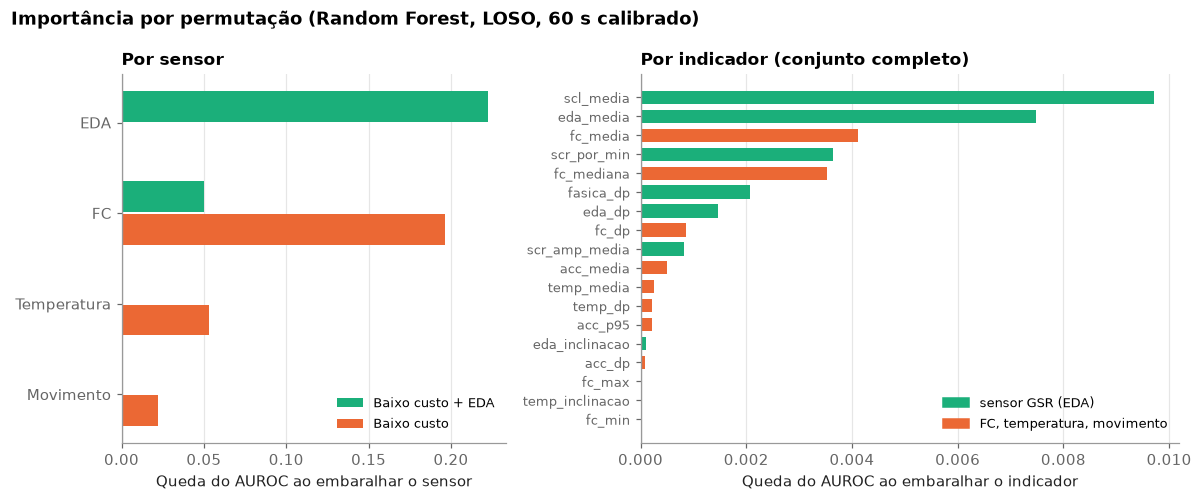

Por sensor (média entre participantes):
             Baixo custo + EDA  Baixo custo
EDA                  2.225e-01          NaN
FC                   5.030e-02        0.196
Movimento            7.000e-04        0.022
Temperatura          1.000e-03        0.053

Por indicador, 8 maiores:
gsr__scl_media      9.700e-03
gsr__eda_media      7.500e-03
bc__fc_media        4.100e-03
gsr__scr_por_min    3.600e-03
bc__fc_mediana      3.500e-03
gsr__fasica_dp      2.100e-03
gsr__eda_dp         1.500e-03
bc__fc_dp           9.000e-04
dtype: float64


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})

ax = axes[0]
med = pd.DataFrame({"Baixo custo + EDA": imp_sensor.mean(), "Baixo custo": imp_sensor_bc.mean()})
ordem = ["EDA", "FC", "Temperatura", "Movimento"]
yy = np.arange(len(ordem))
for k, (col, cor, d) in enumerate([("Baixo custo + EDA", COR["baixo_custo_eda"], -0.18),
                                   ("Baixo custo", COR["baixo_custo"], 0.18)]):
    v = med[col].reindex(ordem)
    ax.barh(yy + d, v.fillna(0), height=0.34, color=cor, label=col)
ax.set_yticks(yy, ordem)
ax.invert_yaxis()
ax.axvline(0, color="#999999", lw=0.8)
ax.set_xlabel("Queda do AUROC ao embaralhar o sensor")
ax.set_title("Por sensor", loc="left")
ax.legend(fontsize=8.5, loc="lower right")
ax.grid(axis="y", visible=False)

ax = axes[1]
r = imp_ind.mean().sort_values(ascending=False)
cores = [COR["baixo_custo_eda"] if c.startswith("gsr__") else COR["baixo_custo"] for c in r.index]
ax.barh(np.arange(len(r)), r.values, color=cores, height=0.7)
ax.set_yticks(np.arange(len(r)), [c.split("__")[1] for c in r.index], fontsize=8.5)
ax.invert_yaxis()
ax.axvline(0, color="#999999", lw=0.8)
ax.set_xlabel("Queda do AUROC ao embaralhar o indicador")
ax.set_title("Por indicador (conjunto completo)", loc="left")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COR["baixo_custo_eda"], label="sensor GSR (EDA)"),
                   Patch(color=COR["baixo_custo"], label="FC, temperatura, movimento")],
          fontsize=8.5, loc="lower right")
fig.suptitle("Importância por permutação (Random Forest, LOSO, 60 s calibrado)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_importancia.png")
plt.show()

print("Por sensor (média entre participantes):")
print(med.round(4))
print("\nPor indicador, 8 maiores:")
print(r.head(8).round(4))

## 5. Ao longo da sessão: tempo até o alerta e alarmes falsos

Aqui simulamos o uso: a pulseira gera uma probabilidade de estresse a cada 30 s, e o professor recebe um alerta quando ela passa de 0,5. Para ver a sessão inteira, refazemos o LOSO prevendo **todas** as janelas do participante de teste, inclusive a **meditação**, que não entra no treino (é repouso, mas com respiração guiada).

Duas regras de alerta:

- **imediata**: alerta na primeira janela acima de 0,5;
- **2 seguidas**: alerta só quando duas janelas consecutivas passam de 0,5 (30 s a mais de espera, em troca de menos alarmes falsos).

**Limitação importante:** o WESAD não tem um período "antes da crise". O que medimos é a **demora para detectar** o estresse depois que ele começa, e não a **antecedência** em relação a uma crise, que é o que Goodwin et al. (2019) e Imbiriba et al. (2023) medem em jovens com TEA.

In [11]:
bruto = pd.read_csv(FEATURES)
bruto = bruto[bruto.janela_valida].reset_index(drop=True)
todas = sorted({c for v in sets.values() for c in v})
sessao = normalizar_por_baseline(bruto, todas)
sessao = sessao[~sessao.calibracao].reset_index(drop=True)


def loso_sessao(sessao, cols, nome_modelo="rf"):
    """Probabilidade LOSO para todas as janelas (treino só com as janelas binárias dos outros)."""
    prob = np.full(len(sessao), np.nan)
    for s in sessao.subject.unique():
        tr = (sessao.subject != s) & sessao.estresse.notna()
        te = sessao.subject == s
        y = sessao.loc[tr, "estresse"].astype(int).to_numpy()
        m = modelos((y == 0).sum() / (y == 1).sum())[nome_modelo]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m.fit(sessao.loc[tr, cols].to_numpy(), y)
        prob[te.to_numpy()] = m.predict_proba(sessao.loc[te, cols].to_numpy())[:, 1]
    return prob


for c in CONJ:
    sessao[f"prob__{c}"] = loso_sessao(sessao, sets[c])

# início do estresse (rótulo 2) direto dos rótulos do WESAD
inicio_estresse = {}
for s in SUBJECTS:
    eda = load_wrist(s)["EDA"]
    inicio_estresse[s] = eda.loc[eda.label == 2, "t"].min()
sessao["t_fim"] = sessao.t_inicio + sessao.janela_s
print(f"{len(sessao)} janelas avaliadas na sessão inteira:", sessao.condicao.value_counts().to_dict())

1078 janelas avaliadas na sessão inteira: {'baseline': 399, 'meditacao': 278, 'estresse': 274, 'diversao': 127}


In [12]:
def alertas(g, col, seguidas=1, limiar=0.5):
    """Marca as janelas em que o alerta dispara (exige `seguidas` janelas consecutivas acima do limiar)."""
    g = g.sort_values("t_inicio")
    acima = (g[col] >= limiar).to_numpy()
    consecutiva = np.r_[False, np.isclose(np.diff(g.t_inicio.to_numpy()), 30)]
    corrida = np.zeros(len(g), int)
    for i in range(len(g)):
        corrida[i] = (corrida[i - 1] + 1 if (i and consecutiva[i]) else 1) if acima[i] else 0
    return pd.Series(corrida >= seguidas, index=g.index)


linhas = []
for c in CONJ:
    for seg in (1, 2):
        dispara = pd.concat([alertas(g, f"prob__{c}", seg) for _, g in sessao.groupby("subject")])
        d = sessao.assign(alerta=dispara)
        for s, g in d.groupby("subject"):
            est = g[g.condicao == "estresse"]
            primeiro = est.loc[est.alerta, "t_fim"].min()
            calmo = g[g.condicao.isin(["baseline", "diversao"])]
            med_ = g[g.condicao == "meditacao"]
            linhas.append({"conjunto": c, "regra": f"{seg} janela(s)", "subject": s,
                           "detectou": pd.notna(primeiro),
                           "latencia_min": (primeiro - inicio_estresse[s]) / 60,
                           "sensibilidade": est.alerta.mean(),
                           "alarme_falso_calmo": calmo.alerta.mean(),
                           "alarme_falso_meditacao": med_.alerta.mean()})
uso = pd.DataFrame(linhas)

resumo_uso = (uso.groupby(["conjunto", "regra"])
              .agg(participantes_detectados=("detectou", "sum"),
                   latencia_mediana_min=("latencia_min", "median"),
                   latencia_max_min=("latencia_min", "max"),
                   janelas_estresse_com_alerta=("sensibilidade", "mean"),
                   alarme_falso_baseline_diversao=("alarme_falso_calmo", "mean"),
                   alarme_falso_meditacao=("alarme_falso_meditacao", "mean"))
              .reindex(CONJ, level=0).rename(index=NOME1, level=0))
resumo_uso.to_csv(MET_DIR / "02_uso_alertas.csv")
resumo_uso

participantes_detectados  \
conjunto                   regra                                   
Só FC                      1 janela(s)                        15   
                           2 janela(s)                        15   
Baixo custo (FC+temp+mov.) 1 janela(s)                        15   
                           2 janela(s)                        15   
Baixo custo + EDA          1 janela(s)                        15   
                           2 janela(s)                        15   

                                        latencia_mediana_min  \
conjunto                   regra                               
Só FC                      1 janela(s)                 1.296   
                           2 janela(s)                 1.887   
Baixo custo (FC+temp+mov.) 1 janela(s)                 1.346   
                           2 janela(s)                 1.846   
Baixo custo + EDA          1 janela(s)                 1.296   
                           2 janela(s)                 1.796   

                                        latencia_max_min  \
conjunto                   regra                           
Só FC                      1 janela(s)             1.821   
                           2 janela(s)             4.346   
Baixo custo (FC+temp+mov.) 1 janela(s)             6.821   
                           2 janela(s)             7.321   
Baixo custo + EDA          1 janela(s)             5.104   
                           2 janela(s)             5.604   

                                        janelas_estresse_com_alerta  \
conjunto                   regra                                      
Só FC                      1 janela(s)                        0.778   
                           2 janela(s)                        0.661   
Baixo custo (FC+temp+mov.) 1 janela(s)                        0.760   
                           2 janela(s)                        0.669   
Baixo custo + EDA          1 janela(s)                        0.941   
                           2 janela(s)                        0.864   

                                        alarme_falso_baseline_diversao  \
conjunto                   regra                                         
Só FC                      1 janela(s)                           0.133   
                           2 janela(s)                           0.056   
Baixo custo (FC+temp+mov.) 1 janela(s)                           0.098   
                           2 janela(s)                           0.049   
Baixo custo + EDA          1 janela(s)                           0.041   
                           2 janela(s)                           0.028   

                                        alarme_falso_meditacao  
conjunto                   regra                                
Só FC                      1 janela(s)                   0.070  
                           2 janela(s)                   0.023  
Baixo custo (FC+temp+mov.) 1 janela(s)                   0.234  
                           2 janela(s)                   0.167  
Baixo custo + EDA          1 janela(s)                   0.073  
                           2 janela(s)                   0.049

A latência conta do início do rótulo de estresse até o **fim** da janela que dispara o alerta, porque é só nesse momento que a pulseira tem os 60 s de dados. Por isso, mesmo um modelo perfeito tem latência mínima de cerca de 1 minuto com janelas de 60 s. As taxas de alarme falso são a fração de janelas calmas em que o alerta estaria ativo.

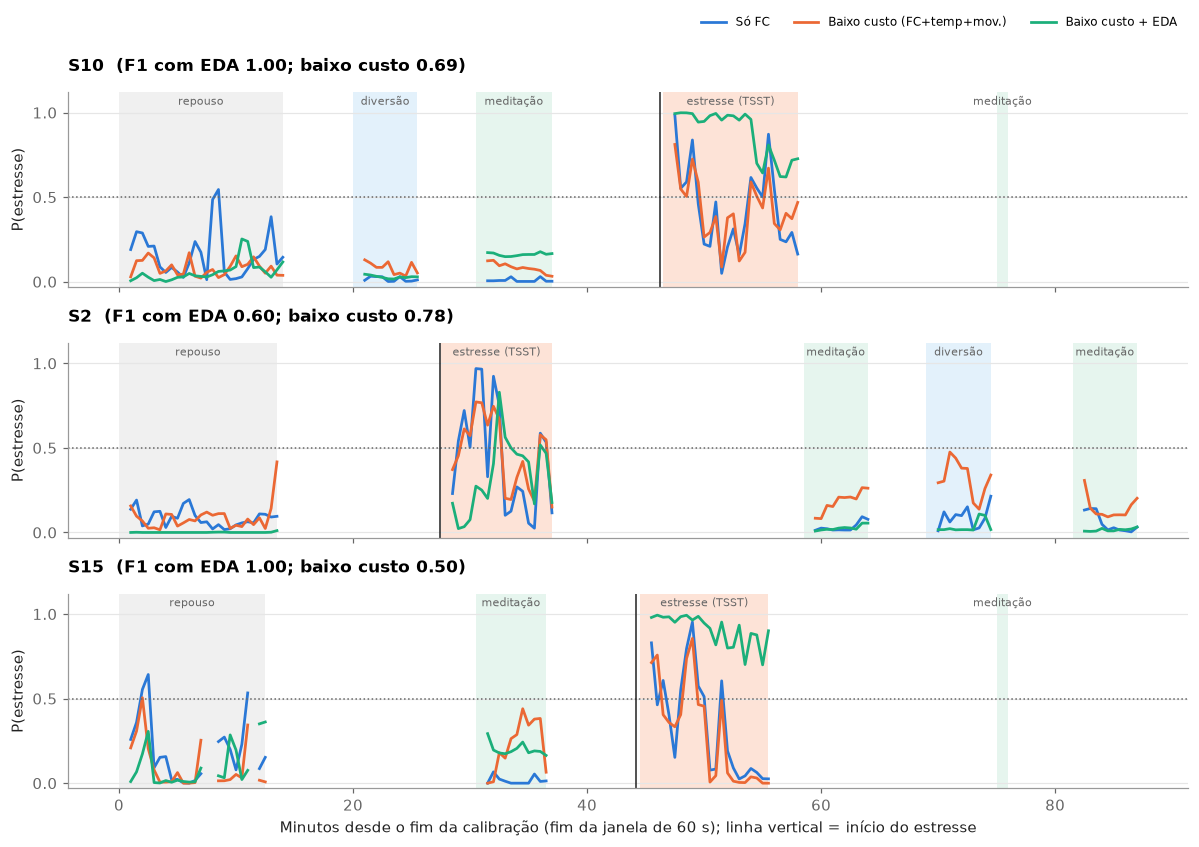

In [13]:
COND_COR = {"baseline": "#f0f0f0", "estresse": "#fde3d7", "diversao": "#e3f1fb", "meditacao": "#e6f5ee"}
COND_NOME = {"baseline": "repouso", "estresse": "estresse (TSST)", "diversao": "diversão", "meditacao": "meditação"}


def plot_sessao(ax, s):
    g = sessao[sessao.subject == s].sort_values("t_inicio")
    t0 = g.t_inicio.min()
    # faixas das condições (pela janela)
    for cond, gg in g.groupby((g.condicao != g.condicao.shift()).cumsum()):
        ax.axvspan((gg.t_inicio.min() - t0) / 60, (gg.t_fim.max() - t0) / 60,
                   color=COND_COR[gg.condicao.iloc[0]], lw=0, zorder=0)
        meio = ((gg.t_inicio.min() + gg.t_fim.max()) / 2 - t0) / 60
        ax.text(meio, 1.03, COND_NOME[gg.condicao.iloc[0]], ha="center", va="bottom", fontsize=7.5, color=TINTA2)
    for c in CONJ:
        # quebra a linha onde há janelas faltando
        gap = np.r_[False, np.diff(g.t_inicio) > 31]
        tt = ((g.t_fim - t0) / 60).to_numpy().astype(float)
        pp_ = g[f"prob__{c}"].to_numpy().astype(float)
        tt, pp_ = np.insert(tt, np.where(gap)[0], np.nan), np.insert(pp_, np.where(gap)[0], np.nan)
        ax.plot(tt, pp_, color=COR[c], lw=1.8, label=NOME1[c])
    ax.axhline(0.5, color=TINTA2, ls=":", lw=1)
    ax.axvline((inicio_estresse[s] - t0) / 60, color=TINTA, lw=1)
    ax.set_ylim(-0.03, 1.12)
    ax.set_yticks([0, 0.5, 1])
    ax.grid(axis="x", visible=False)
    ax.set_ylabel("P(estresse)")
    ax.set_title(f"{s}  (F1 com EDA {pp.loc[s, 'baixo_custo_eda']:.2f}; baixo custo {pp.loc[s, 'baixo_custo']:.2f})",
                 loc="left", pad=14)


exemplos = [pp.baixo_custo_eda.sub(pp.baixo_custo_eda.median()).abs().idxmin(), "S2", "S15"]
fig, axes = plt.subplots(len(exemplos), 1, figsize=(11, 2.6 * len(exemplos)), sharex=True)
for ax, s in zip(axes, exemplos):
    plot_sessao(ax, s)
axes[0].legend(loc="upper right", fontsize=8, ncol=3, bbox_to_anchor=(1, 1.45))
axes[-1].set_xlabel("Minutos desde o fim da calibração (fim da janela de 60 s); linha vertical = início do estresse")
fig.tight_layout()
fig.savefig(FIG_DIR / "02_sessao_probabilidade.png")
plt.show()

## 6. Modelo final para a demonstração IoT

Escolha: **Random Forest no conjunto `baixo_custo_eda`, calibrado por pessoa**. Motivos:

- melhor F1 macro e AUROC no LOSO principal, com o menor desvio entre participantes;
- melhor modelo de Schmidt et al. (2018) no pulso, o que facilita a comparação na Seção 4;
- os sensores (pulso óptico, temperatura, acelerômetro e GSR) existem em versão barata para ESP32.

O modelo é treinado com todos os 15 participantes e salvo em `models/modelo_estresse.joblib`. Na demonstração, a pulseira virtual precisa de 5 minutos de repouso no início para a calibração.

In [14]:
from src.models.train import salvar_modelo
caminho = salvar_modelo(df, sets, "rf", "baixo_custo_eda", normalizado=True)
print("salvo em", caminho.relative_to(ROOT))

salvo em models/modelo_estresse.joblib


## 7. Conclusões

**Resposta à pergunta central.** Na configuração principal (60 s, calibrado, melhor modelo de cada conjunto):

| Conjunto | F1 macro | AUROC | Perda de F1 vs. completo |
|---|---|---|---|
| Só FC | 0,826 | 0,892 | −0,12 |
| Baixo custo (FC + temperatura + movimento) | 0,835 | 0,907 | −0,11 |
| Baixo custo + EDA | **0,948** | **0,988** | — |

Todos ficam muito acima da classe majoritária (F1 0,40).

1. **O sensor que faz a diferença é o de EDA (GSR), não a temperatura nem o movimento.** Somar temperatura e movimento à FC quase não muda o resultado calibrado (+0,01). Somar a EDA leva o F1 de ~0,83 para ~0,95. Na importância por permutação, embaralhar a EDA derruba o AUROC em 0,22. A FC vem em seguida (0,05 com EDA; 0,20 quando a EDA não existe). Temperatura e movimento ficam perto de zero.

2. **A EDA só ajuda quando calibrada pela pessoa.** Sem calibração, o conjunto com EDA cai para 0,88 e empata com o baixo custo (0,89), porque o nível de condutância da pele varia muito entre pessoas. Já os conjuntos sem EDA não ganham com a calibração (0,83 calibrado contra 0,83–0,89 bruto): a FC absoluta já generaliza razoavelmente. Para a pulseira escolar, isso significa que **o GSR exige uma calibração em repouso no início do dia**.

3. **Sem EDA, o resultado é instável.** O F1 do baixo custo vai de 0,83 a 0,90 dependendo da janela e da calibração. Com EDA e calibração, fica em ~0,95 nas duas janelas (0,948 com 60 s; 0,952 com 120 s).

4. **A variação entre pessoas é grande, e a EDA reduz justamente os piores casos.** Sem EDA, o pior participante tem F1 0,48 (S6) e o desvio entre pessoas é 0,17. Com EDA, 12 dos 15 participantes passam de 0,94, e o desvio cai para 0,11. Os casos difíceis sem EDA são **S6** e **S15**, que, segundo as anotações do WESAD, não ficaram realmente estressados com o TSST (S6 já tinha feito muitas entrevistas; S15 não acreditou na encenação). Neles a FC quase não subiu (+1,5 e +5,9 bpm), mas a EDA subiu. O pior caso com EDA é **S2** (0,60), que teve resposta eletrodérmica fraca e não tem anotação que explique. Ou seja, nenhum conjunto funciona para todas as pessoas.

5. **Uso simulado da pulseira.** Com alerta a cada janela acima de 0,5, o modelo detectou o estresse nos 15 participantes, com todos os conjuntos.

   | Conjunto | Latência mediana (máx.) | Janelas de estresse com alerta | Alarme falso: repouso/diversão | Alarme falso: meditação |
   |---|---|---|---|---|
   | Só FC | 1,3 min (1,8 min) | 78% | 13% | 7% |
   | Baixo custo | 1,3 min (6,8 min) | 76% | 10% | 23% |
   | Baixo custo + EDA | 1,3 min (5,1 min) | 94% | 4% | 7% |

   - **Regra "2 janelas seguidas":** custa ~30 s a mais e reduz os alarmes falsos com EDA para 2,8% (repouso/diversão) e 4,9% (meditação). É a regra recomendada para a demonstração.
   - **Latência:** é quase toda o tamanho da janela (60 s).
   - **Alarmes falsos na meditação:** a taxa alta do baixo custo (23%) sugere que temperatura e movimento confundem calma com estresse fora das condições de treino.

6. **Comparação com a literatura.** Sem calibração, a Random Forest com todos os sensores de pulso alcança F1 0,87, contra 0,86 de Schmidt et al. (2018). Isso valida o pipeline, e a calibração por pessoa acrescenta cerca de 0,07.

**O que isso sugere para a pulseira escolar.** Uma pulseira com sensor de pulso óptico e **sensor GSR**, calibrada em 5 min de repouso, chega perto da pulseira de pesquisa nessas condições. Só com FC já se detecta o estresse na maioria das pessoas, mas com mais alarmes falsos e falhas nas pessoas que reagem pouco no coração. Temperatura e movimento acrescentam pouco.

**Limitações (para a Seção 4 e as Conclusões):**
- o "baixo custo" é **simulado** com sinais da E4: sensores baratos reais são mais ruidosos, e GSR no pulso costuma ter mau contato. Os números são um teto;
- são **15 adultos jovens neurotípicos** sob estresse de laboratório (TSST), não crianças com TEA em sala de aula;
- mede-se **latência de detecção, não antecedência** de crise (o WESAD não tem período pré-crise);
- o filtro da EDA não é causal (`filtfilt`): na pulseira real seria preciso um filtro causal;
- a fração de janelas descartadas por ruído é desigual entre condições (diversão 18,6%, estresse 9,3%, repouso 1,8%);
- a importância por indicador é pequena porque os indicadores do mesmo sensor são redundantes (embaralhar um deixa os outros). Por isso a análise por sensor é a mais informativa.

**Modelo salvo:** `models/modelo_estresse.joblib` (Random Forest, `baixo_custo_eda`, calibrado).